# Challenge 2 — Détection de fraude explicable (Sparkov)

**Plan du notebook** : Module 1 Données → Module 2 Variables & split → Module 3 Modèles → Module 4 Évaluation & seuil métier → Module 5 SHAP → Export des modèles et préparation de l'application locale (Streamlit).


In [ ]:
# Installation des dépendances pour l'entraînement et l'application locale.
!pip -q install shap kagglehub streamlit pyarrow joblib


In [ ]:
import os, glob, json, time, sys, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, fbeta_score, matthews_corrcoef)
from IPython.display import display

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
os.makedirs('artifacts', exist_ok=True)

# ---------- PARAMÈTRES (modifiables) ----------
SEED = 42
FRAC_CARTES = 1.0      # fraction des cartes conservées (0.3 pour un run rapide de test)
COUT_ANALYSE = 10.0    # coût d'analyse d'UNE alerte, en $ (hypothèse métier)
BUDGET_PCT = 1.0       # budget d'alertes k, en % des transactions de la période
np.random.seed(SEED)

# Module 1 — Données


In [ ]:
def charger_sparkov():
    dossier = '.' if glob.glob('fraud*.csv') else None
    if dossier is None:
        try:
            import kagglehub
            dossier = kagglehub.dataset_download('kartik2112/fraud-detection')
        except Exception as e:
            print('Téléchargement automatique impossible :', repr(e)[:150])
            from google.colab import files
            print(' Importez fraudTrain.csv et fraudTest.csv (page Kaggle du jeu).')
            files.upload()
            dossier = '.'
    fichiers = sorted(glob.glob(os.path.join(dossier, '**', 'fraud*.csv'), recursive=True))
    assert fichiers, 'Aucun fichier fraud*.csv trouvé'
    print('Fichiers lus :', [os.path.basename(f) for f in fichiers])
    d = pd.concat([pd.read_csv(f) for f in fichiers], ignore_index=True)
    d = d.drop(columns=[c for c in d.columns if c.startswith('Unnamed')], errors='ignore')
    return d.drop_duplicates(subset='trans_num')

df = charger_sparkov()
df['ts'] = pd.to_datetime(df['trans_date_trans_time'])
df['dob'] = pd.to_datetime(df['dob'])
df['is_fraud'] = df['is_fraud'].astype(int)
if FRAC_CARTES < 1:
    cartes = df['cc_num'].drop_duplicates().sample(frac=FRAC_CARTES, random_state=SEED)
    df = df[df['cc_num'].isin(cartes)]
df = df.sort_values('ts', kind='stable').reset_index(drop=True)

print(f"{len(df):,} transactions | {df.cc_num.nunique()} cartes | {df.merchant.nunique()} marchands")
print(f"Période : {df.ts.min():%Y-%m-%d} → {df.ts.max():%Y-%m-%d}")
print(f"Taux de fraude : {df.is_fraud.mean():.3%}  ({df.is_fraud.sum():,} fraudes)")
display(df.groupby('is_fraud')['amt'].describe().round(2).rename(index={0: 'Légitime', 1: 'Fraude'}))

Using Colab cache for faster access to the 'fraud-detection' dataset.
Fichiers lus : ['fraudTest.csv', 'fraudTrain.csv']
1,852,394 transactions | 999 cartes | 693 marchands
Période : 2019-01-01 → 2020-12-31
Taux de fraude : 0.521%  (9,651 fraudes)


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
Légitime,1842743.0,67.65,153.55,1.00,9.61,47.24,82.56,28948.90
Fraude,9651.0,530.66,391.03,1.06,240.08,390.00,902.36,1376.04


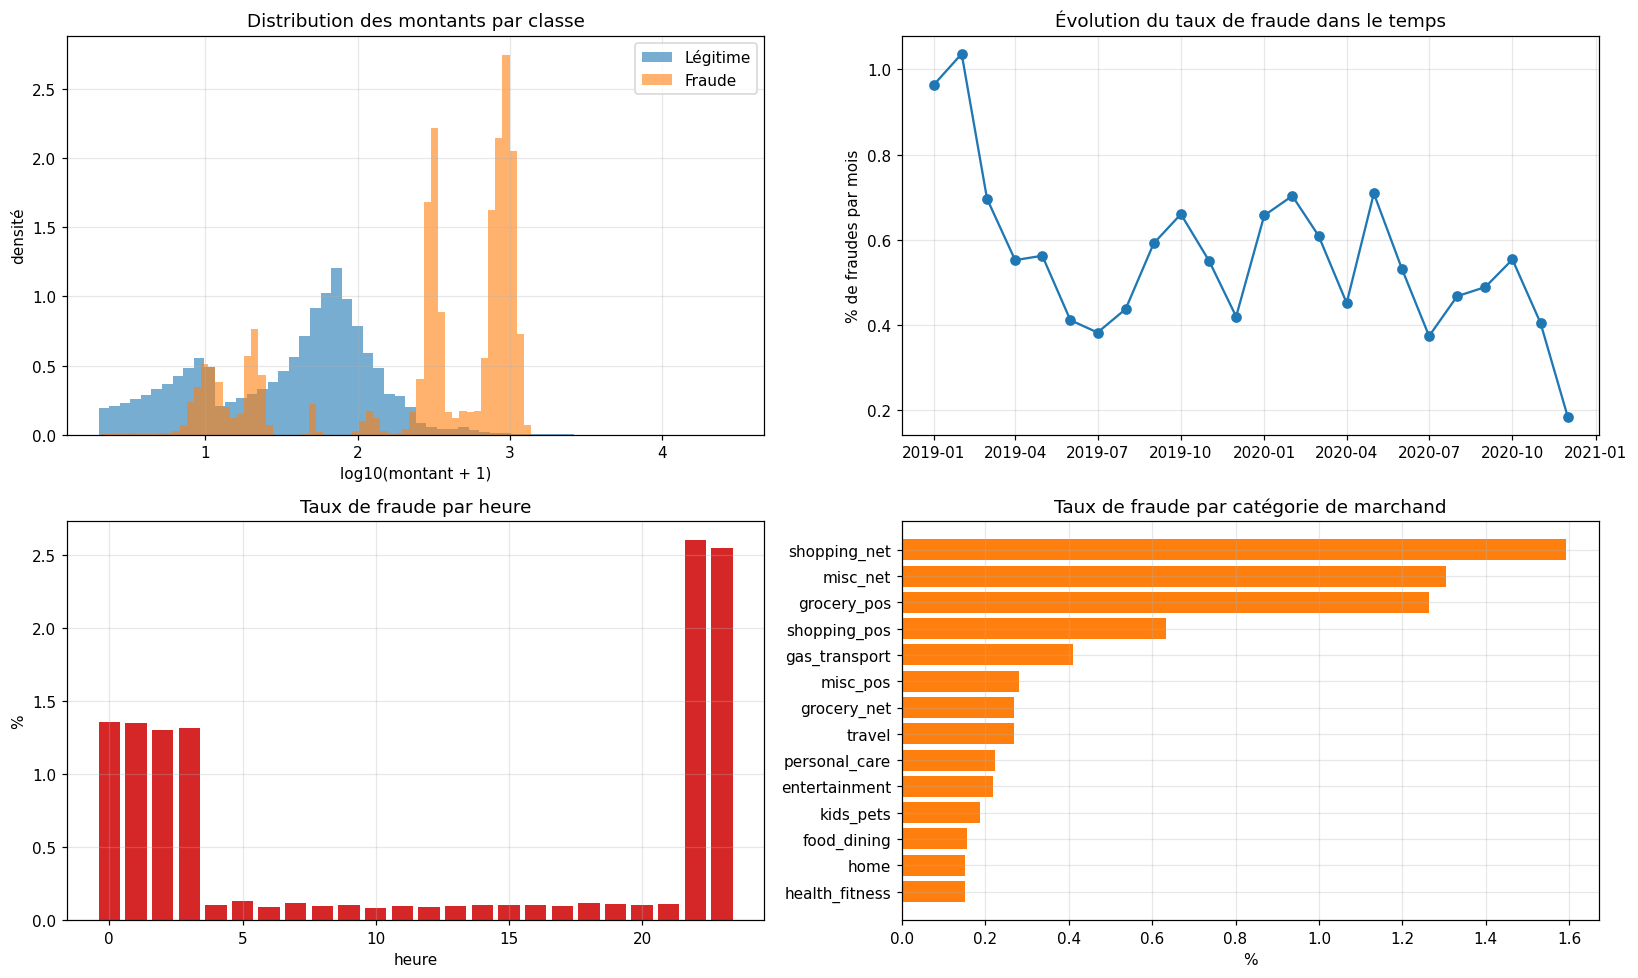

gender
F    0.483
M    0.567


In [ ]:
# Visualisations exploratoires
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

for c, lab in [(0, 'Légitime'), (1, 'Fraude')]:
    ax[0, 0].hist(np.log10(df.loc[df.is_fraud == c, 'amt'] + 1), bins=60, alpha=.6, density=True, label=lab)
ax[0, 0].set(title='Distribution des montants par classe', xlabel='log10(montant + 1)', ylabel='densité')
ax[0, 0].legend()

mois = df.groupby(df.ts.dt.to_period('M')).is_fraud.agg(taux='mean', n_fraudes='sum', n='count')
ax[0, 1].plot(mois.index.to_timestamp(), mois['taux'] * 100, marker='o')
ax[0, 1].set(title='Évolution du taux de fraude dans le temps', ylabel='% de fraudes par mois')

h = df.groupby(df.ts.dt.hour).is_fraud.mean() * 100
ax[1, 0].bar(h.index, h.values, color='tab:red')
ax[1, 0].set(title='Taux de fraude par heure', xlabel='heure', ylabel='%')

cat = (df.groupby('category').is_fraud.mean() * 100).sort_values()
ax[1, 1].barh(cat.index, cat.values, color='tab:orange')
ax[1, 1].set(title='Taux de fraude par catégorie de marchand', xlabel='%')
plt.tight_layout(); plt.show()

# (pas de variable « canal » dans ce jeu : la catégorie de marchand et le genre jouent ce rôle)
print((df.groupby('gender').is_fraud.mean() * 100).round(3).to_string())
mois.reset_index().assign(mois=lambda x: x['ts'].astype(str)).drop(columns='ts').to_csv('artifacts/eda_monthly.csv', index=False)

# Module 2 — Préparation et variables
**Règle anti-fuite** : toute variable comportementale d'une transaction n'utilise que des transactions **strictement antérieures** de la même carte. On peut donc la calculer sur tout le flux avant le découpage sans fuite du futur vers le passé.



In [ ]:
%%writefile fraud_features.py
import numpy as np
import pandas as pd

CATEGORIES = ['entertainment', 'food_dining', 'gas_transport', 'grocery_net', 'grocery_pos',
              'health_fitness', 'home', 'kids_pets', 'misc_net', 'misc_pos', 'personal_care',
              'shopping_net', 'shopping_pos', 'travel']

FEATURES = (['amt', 'amt_ratio_30d', 'heures_depuis_prec', 'cnt_1h', 'cnt_24h', 'dist_km',
             'hour_sin', 'hour_cos', 'dow', 'is_weekend', 'is_night', 'age', 'city_pop', 'gender_M']
            + ['cat_' + c for c in CATEGORIES])

LIBELLES = {
    'amt': 'Montant de la transaction',
    'amt_ratio_30d': 'Montant rapporté à la moyenne des 30 derniers jours',
    'heures_depuis_prec': 'Temps écoulé depuis la transaction précédente (h)',
    'cnt_1h': 'Nb de transactions sur la dernière heure',
    'cnt_24h': 'Nb de transactions sur les dernières 24 h',
    'dist_km': 'Distance client – marchand (km)',
    'hour_sin': "Heure de la journée (composante sinus)",
    'hour_cos': "Heure de la journée (composante cosinus)",
    'dow': 'Jour de la semaine',
    'is_weekend': 'Transaction le week-end',
    'is_night': 'Transaction de nuit (22h-3h)',
    'age': 'Âge du porteur',
    'city_pop': 'Population de la ville du client',
    'gender_M': 'Genre (homme)',
}
LIBELLES.update({'cat_' + c: 'Catégorie marchand : ' + c for c in CATEGORIES})


def derive(df):
    """Construit la matrice de variables à partir des colonnes de base :
    ts, amt, category, gender, city_pop, dist_km, age, cnt_1h, cnt_24h,
    mean_amt_30d (peut être NaN), heures_depuis_prec (peut être NaN)."""
    ts = pd.to_datetime(df['ts'])
    out = pd.DataFrame(index=df.index)
    out['amt'] = df['amt'].astype(float)
    ratio = out['amt'] / df['mean_amt_30d'].astype(float)
    out['amt_ratio_30d'] = ratio.replace([np.inf, -np.inf], np.nan).fillna(1.0)
    out['heures_depuis_prec'] = df['heures_depuis_prec'].astype(float).fillna(24 * 30)
    out['cnt_1h'] = df['cnt_1h'].astype(float)
    out['cnt_24h'] = df['cnt_24h'].astype(float)
    out['dist_km'] = df['dist_km'].astype(float)
    h = ts.dt.hour + ts.dt.minute / 60.0
    out['hour_sin'] = np.sin(2 * np.pi * h / 24)      # codage cyclique de l'heure
    out['hour_cos'] = np.cos(2 * np.pi * h / 24)
    out['dow'] = ts.dt.dayofweek
    out['is_weekend'] = (out['dow'] >= 5).astype(int)
    out['is_night'] = ((ts.dt.hour >= 22) | (ts.dt.hour <= 3)).astype(int)
    out['age'] = df['age'].astype(float)
    out['city_pop'] = df['city_pop'].astype(float)
    out['gender_M'] = (df['gender'] == 'M').astype(int)
    for c in CATEGORIES:
        out['cat_' + c] = (df['category'] == c).astype(int)
    return out[FEATURES]


def codes_motifs(contrib_row, values_row, n=5):
    """Codes motifs : les n variables qui poussent le plus le score vers « fraude ».
    contrib_row : contributions (xgboost pred_contribs, dernier élément = biais)."""
    nf = len(FEATURES)
    c = np.asarray(contrib_row)[:nf]
    ordre = np.argsort(-c)
    res = [i for i in ordre if c[i] > 0][:n]
    for i in ordre:                     # on complète jusqu'à 3 motifs minimum
        if len(res) >= 3:
            break
        if i not in res:
            res.append(i)
    return [{'code': f'M{rang + 1}', 'variable': FEATURES[i], 'motif': LIBELLES[FEATURES[i]],
             'valeur': round(float(values_row[i]), 3), 'contribution': round(float(c[i]), 3)}
            for rang, i in enumerate(res)]

Writing fraud_features.py


In [ ]:
import fraud_features as ff
from fraud_features import FEATURES, derive, codes_motifs

def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2
         + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 12742 * np.arcsin(np.sqrt(a))

def ajouter_variables_comportementales(d):
    """Pour chaque transaction : nb de transactions de la même carte sur 1 h / 24 h,
    moyenne des montants sur 30 jours, temps depuis la transaction précédente.
    Fenêtres calculées sur le PASSÉ STRICT de la carte (la transaction courante est exclue)."""
    d = d.sort_values(['cc_num', 'ts'], kind='stable').copy()
    t = d['ts'].values.astype('datetime64[s]').astype('int64')
    a = d['amt'].values.astype(float)
    cartes = d['cc_num'].values
    n = len(d)
    cnt1h, cnt24h = np.zeros(n), np.zeros(n)
    moy30 = np.full(n, np.nan)
    dt_prec = np.full(n, np.nan)
    bornes = np.flatnonzero(np.r_[True, cartes[1:] != cartes[:-1], True])
    for s, e in zip(bornes[:-1], bornes[1:]):
        tt, aa = t[s:e], a[s:e]
        i = np.arange(e - s)
        cnt1h[s:e] = i - np.searchsorted(tt, tt - 3600, side='left')
        cnt24h[s:e] = i - np.searchsorted(tt, tt - 86400, side='left')
        lo = np.searchsorted(tt, tt - 30 * 86400, side='left')
        cs = np.r_[0.0, np.cumsum(aa)]
        c30 = i - lo
        moy30[s:e] = np.where(c30 > 0, (cs[i] - cs[lo]) / np.maximum(c30, 1), np.nan)
        dt_prec[s + 1:e] = np.diff(tt)
    d['cnt_1h'], d['cnt_24h'], d['mean_amt_30d'] = cnt1h, cnt24h, moy30
    d['heures_depuis_prec'] = dt_prec / 3600.0
    d['dist_km'] = haversine_km(d['lat'], d['long'], d['merch_lat'], d['merch_long'])
    d['age'] = (d['ts'] - d['dob']).dt.days / 365.25
    return d.sort_values('ts', kind='stable').reset_index(drop=True)

t0 = time.time()
df = ajouter_variables_comportementales(df)
X_all = derive(df)
y_all = df['is_fraud'].values
print(f'Variables construites en {time.time()-t0:.0f}s ->', X_all.shape)
display(X_all.groupby(y_all).mean().T.round(3).rename(columns={0: 'moy. légitime', 1: 'moy. fraude'}).head(14))

Variables construites en 9s -> (1852394, 28)


,moy. légitime,moy. fraude
amt,67.651,530.661
amt_ratio_30d,1.032,5.623
heures_depuis_prec,8.959,12.602
cnt_1h,0.198,0.677
cnt_24h,4.110,4.305
dist_km,76.111,76.256
hour_sin,-0.138,-0.009
hour_cos,-0.001,0.729
dow,2.967,3.106
is_weekend,0.328,0.319


### Séparation chronologique 60 % / 20 % / 20 %
Les transactions sont triées par date : l'entraînement = le passé, la validation = le futur proche (choix du modèle et du seuil), le test = le futur lointain (jugement final, jamais utilisé pour décider). Une séparation aléatoire serait ici **inadaptée** : le jeu a un horodatage, et mélanger passé et futur gonflerait artificiellement les scores.

In [ ]:
n = len(df); i1, i2 = int(.6 * n), int(.8 * n)
Xtr, Xva, Xte = X_all.iloc[:i1], X_all.iloc[i1:i2], X_all.iloc[i2:]
ytr, yva, yte = y_all[:i1], y_all[i1:i2], y_all[i2:]
amt_va, amt_te = df['amt'].values[i1:i2], df['amt'].values[i2:]

recap = pd.DataFrame({
    'début': [df.ts.iloc[0], df.ts.iloc[i1], df.ts.iloc[i2]],
    'fin': [df.ts.iloc[i1 - 1], df.ts.iloc[i2 - 1], df.ts.iloc[-1]],
    'transactions': [len(ytr), len(yva), len(yte)],
    'fraudes': [ytr.sum(), yva.sum(), yte.sum()],
    'taux fraude %': [ytr.mean() * 100, yva.mean() * 100, yte.mean() * 100]},
    index=['train (60 %)', 'val (20 %)', 'test (20 %)']).round(3)
display(recap)

,début,fin,transactions,fraudes,taux fraude %
train (60 %),2019-01-01 00:00:18,2020-04-07 07:00:14,1111436,6401,0.576
val (20 %),2020-04-07 07:00:36,2020-08-25 01:31:21,370479,1901,0.513
test (20 %),2020-08-25 01:31:59,2020-12-31 23:59:34,370479,1349,0.364


In [ ]:
# ---------- Fonctions de métriques et de coût (utilisées partout dans la suite) ----------
def k_budget(taille):
    return max(1, int(round(BUDGET_PCT / 100 * taille)))

def pr_at_k(y, s, k):
    """précision@k et rappel@k : on n'examine que les k transactions les mieux scorées."""
    top = np.argpartition(-s, k - 1)[:k]
    tp = y[top].sum()
    return tp / k, tp / max(y.sum(), 1)

def courbe_cout(y, amt, s, c):
    """Coût total si l'on traite les j premières alertes (j = 0..N) :
    coût = montants des fraudes manquées + c × nombre d'alertes analysées."""
    o = np.argsort(-s, kind='stable')
    cum = np.cumsum((amt * y)[o])
    j = np.arange(1, len(y) + 1)
    return s[o], np.r_[cum[-1], cum[-1] - cum + c * j]

def seuil_optimal(y, amt, s, c):
    ss, cout = courbe_cout(y, amt, s, c)
    j = int(np.argmin(cout))
    return (np.inf if j == 0 else ss[j - 1]), cout[j], cout[0]

def cout_au_seuil(y, amt, s, thr, c):
    a = s >= thr
    manque = amt[(y == 1) & ~a].sum()
    return manque + c * a.sum(), manque, int(a.sum())

def cout_vs_seuil(y, amt, s, c, grille):
    o = np.argsort(s); ss = s[o]; fa = np.cumsum((amt * y)[o])
    pos = np.searchsorted(ss, grille, side='left')       # nb de scores < seuil
    return np.where(pos > 0, fa[np.maximum(pos - 1, 0)], 0.0) + c * (len(s) - pos)

def metriques_seuil(y, s, thr):
    a = (s >= thr).astype(int)
    return {'alertes': int(a.sum()), 'précision': precision_score(y, a, zero_division=0),
            'rappel': recall_score(y, a, zero_division=0), 'F2': fbeta_score(y, a, beta=2, zero_division=0),
            'MCC': matthews_corrcoef(y, a) if a.sum() > 0 else 0.0}

print(f"Budget d'alertes k = {BUDGET_PCT}% -> {k_budget(len(yva)):,} alertes sur la validation, {k_budget(len(yte)):,} sur le test")

Budget d'alertes k = 1.0% -> 3,705 alertes sur la validation, 3,705 sur le test


### Stratégie contre le déséquilibre (appliquée **uniquement au jeu d'entraînement**)


In [ ]:
neg, pos = int((ytr == 0).sum()), int(ytr.sum())

def sous_echantillonner(X, y, ratio=10):
    rng = np.random.RandomState(SEED)
    ip, ineg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    ineg = rng.choice(ineg, size=min(len(ineg), ratio * len(ip)), replace=False)
    idx = np.sort(np.r_[ip, ineg])
    return X.iloc[idx], y[idx]

def fit_xgb(X, y, spw=1.0):
    m = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                      colsample_bytree=0.8, tree_method='hist', scale_pos_weight=spw,
                      eval_metric='aucpr', n_jobs=-1, random_state=SEED)
    return m.fit(X, y)

strategies = {
    'Aucune': dict(spw=1.0, under=False),
    'Poids √(neg/pos)': dict(spw=float(np.sqrt(neg / pos)), under=False),
    'Poids neg/pos': dict(spw=neg / pos, under=False),
    'Sous-échantillonnage 10:1': dict(spw=1.0, under=True),
}
modeles_imb, lignes = {}, []
kva = k_budget(len(yva))
for nom, p in strategies.items():
    t0 = time.time()
    Xf, yf = sous_echantillonner(Xtr, ytr) if p['under'] else (Xtr, ytr)
    m = fit_xgb(Xf, yf, p['spw'])
    s = m.predict_proba(Xva)[:, 1]
    pk, rk = pr_at_k(yva, s, kva)
    lignes.append({'stratégie': nom, 'PR-AUC (val)': average_precision_score(yva, s),
                   'ROC-AUC (val)': roc_auc_score(yva, s), f'précision@k': pk, 'rappel@k': rk,
                   'temps (s)': time.time() - t0})
    modeles_imb[nom] = m
comp_imb = pd.DataFrame(lignes).set_index('stratégie').round(4)
display(comp_imb)
MEILLEURE = comp_imb['PR-AUC (val)'].idxmax()
print(f"✅ Stratégie retenue (meilleure PR-AUC en validation) : {MEILLEURE}")

,PR-AUC (val),ROC-AUC (val),précision@k,rappel@k,temps (s)
stratégie,,,,,
Aucune,0.9461,0.9989,0.4947,0.9642,47.3285
Poids √(neg/pos),0.9492,0.9991,0.4950,0.9648,43.1375
Poids neg/pos,0.9455,0.9991,0.4969,0.9684,44.8468
Sous-échantillonnage 10:1,0.9439,0.9989,0.4953,0.9653,5.7641


✅ Stratégie retenue (meilleure PR-AUC en validation) : Poids √(neg/pos)


# Module 3 — Modélisation
* **Supervisés** : régression logistique pondérée (baseline interprétable) et XGBoost (stratégie retenue ci-dessus).
* **Non supervisés** (aucune étiquette utilisée à l'entraînement) :

In [ ]:
def X_lineaire(X):
    Z = X.copy()
    for c in ['amt', 'dist_km', 'city_pop', 'heures_depuis_prec', 'amt_ratio_30d']:
        Z[c] = np.log1p(Z[c])
    return Z

scaler = StandardScaler().fit(X_lineaire(Xtr))
Ztr, Zva, Zte = (scaler.transform(X_lineaire(X)) for X in (Xtr, Xva, Xte))

scores, types = {}, {}

# 1) Régression logistique pondérée
t0 = time.time()
lr = LogisticRegression(class_weight='balanced', max_iter=300).fit(Ztr, ytr)
scores['Régression logistique pondérée'] = {'val': lr.predict_proba(Zva)[:, 1], 'test': lr.predict_proba(Zte)[:, 1]}
types['Régression logistique pondérée'] = 'Supervisé'
print(f'LR : {time.time()-t0:.0f}s')

# 2) XGBoost (stratégie retenue)
xgb_model = modeles_imb[MEILLEURE]
NOM_FINAL = 'XGBoost'
scores[NOM_FINAL] = {'val': xgb_model.predict_proba(Xva)[:, 1], 'test': xgb_model.predict_proba(Xte)[:, 1]}
types[NOM_FINAL] = 'Supervisé'

# 3) Isolation Forest — sans étiquettes
t0 = time.time()
iso = IsolationForest(n_estimators=200, max_samples=512, random_state=SEED, n_jobs=-1).fit(Xtr)
scores['Isolation Forest'] = {'val': -iso.score_samples(Xva), 'test': -iso.score_samples(Xte)}
types['Isolation Forest'] = 'Non supervisé'
print(f'IF : {time.time()-t0:.0f}s')

# 4) Autoencodeur (MLP) — sans étiquettes, erreur de reconstruction = score d'anomalie
t0 = time.time()
rng = np.random.RandomState(SEED)
sub = rng.choice(len(Ztr), size=min(200_000, len(Ztr)), replace=False)
ae = MLPRegressor(hidden_layer_sizes=(24, 8, 24), batch_size=512, max_iter=15, random_state=SEED)
ae.fit(Ztr[sub], Ztr[sub])
erreur = lambda Z: ((ae.predict(Z) - Z) ** 2).mean(axis=1)
scores['Autoencodeur (MLP)'] = {'val': erreur(Zva), 'test': erreur(Zte)}
types['Autoencodeur (MLP)'] = 'Non supervisé'
print(f'AE : {time.time()-t0:.0f}s')

LR : 4s
IF : 11s
AE : 7s


# Module 4 — Évaluation et seuil d'alerte
**Métriques** : PR-AUC et ROC-AUC (qualité du classement), précision@k / rappel@k (ce que fait l'analyste avec un budget fixe de k alertes), puis F2 et MCC au seuil retenu.

**Choix de k** : k = 1 % des transactions de la période, soit environ 2× le taux de fraude de base (~0,5 %). Hypothèse : l'équipe d'analystes peut examiner ~1 transaction sur 100 ; au-delà, le coût de revue devient dominant. C'est un paramètre (`BUDGET_PCT`) à faire varier.



In [ ]:
seuils, lignes = {}, []
kte = k_budget(len(yte))
for nom, s in scores.items():
    thr, cout_val, cout0_val = seuil_optimal(yva, amt_va, s['val'], COUT_ANALYSE)
    seuils[nom] = thr
    pk, rk = pr_at_k(yte, s['test'], kte)
    m = metriques_seuil(yte, s['test'], thr)
    cout_te, manque, na = cout_au_seuil(yte, amt_te, s['test'], thr, COUT_ANALYSE)
    base = amt_te[yte == 1].sum()
    lignes.append({'modèle': nom, 'type': types[nom],
                   'PR-AUC val': average_precision_score(yva, s['val']),
                   'PR-AUC test': average_precision_score(yte, s['test']),
                   'ROC-AUC test': roc_auc_score(yte, s['test']),
                   'précision@k': pk, 'rappel@k': rk,
                   'alertes (seuil)': na, 'F2': m['F2'], 'MCC': m['MCC'],
                   'coût test ($)': cout_te, 'économie vs « rien faire » (%)': 100 * (1 - cout_te / base)})
comparatif = pd.DataFrame(lignes).set_index('modèle').sort_values('PR-AUC test', ascending=False)
comparatif.round(4).to_csv('artifacts/comparatif.csv')
print(f"Référence « aucune alerte » : coût test = {amt_te[yte==1].sum():,.0f} $ (toutes les fraudes passent)")
display(comparatif.round(4))

Référence « aucune alerte » : coût test = 733,912 $ (toutes les fraudes passent)


,type,PR-AUC val,PR-AUC test,ROC-AUC test,précision@k,rappel@k,alertes (seuil),F2,MCC,coût test ($),économie vs « rien faire » (%)
modèle,,,,,,,,,,,
XGBoost,Supervisé,0.9492,0.9390,0.9985,0.3538,0.9718,2162,0.8481,0.7496,32663.59,95.5494
Régression logistique pondérée,Supervisé,0.2805,0.2276,0.9232,0.1876,0.5152,6379,0.3316,0.2610,223252.56,69.5805
Isolation Forest,Non supervisé,0.1065,0.0560,0.8839,0.0880,0.2417,22195,0.1510,0.1420,328441.67,55.2478
Autoencodeur (MLP),Non supervisé,0.0161,0.0117,0.6616,0.0219,0.0600,20230,0.0459,0.0318,779826.91,-6.2562


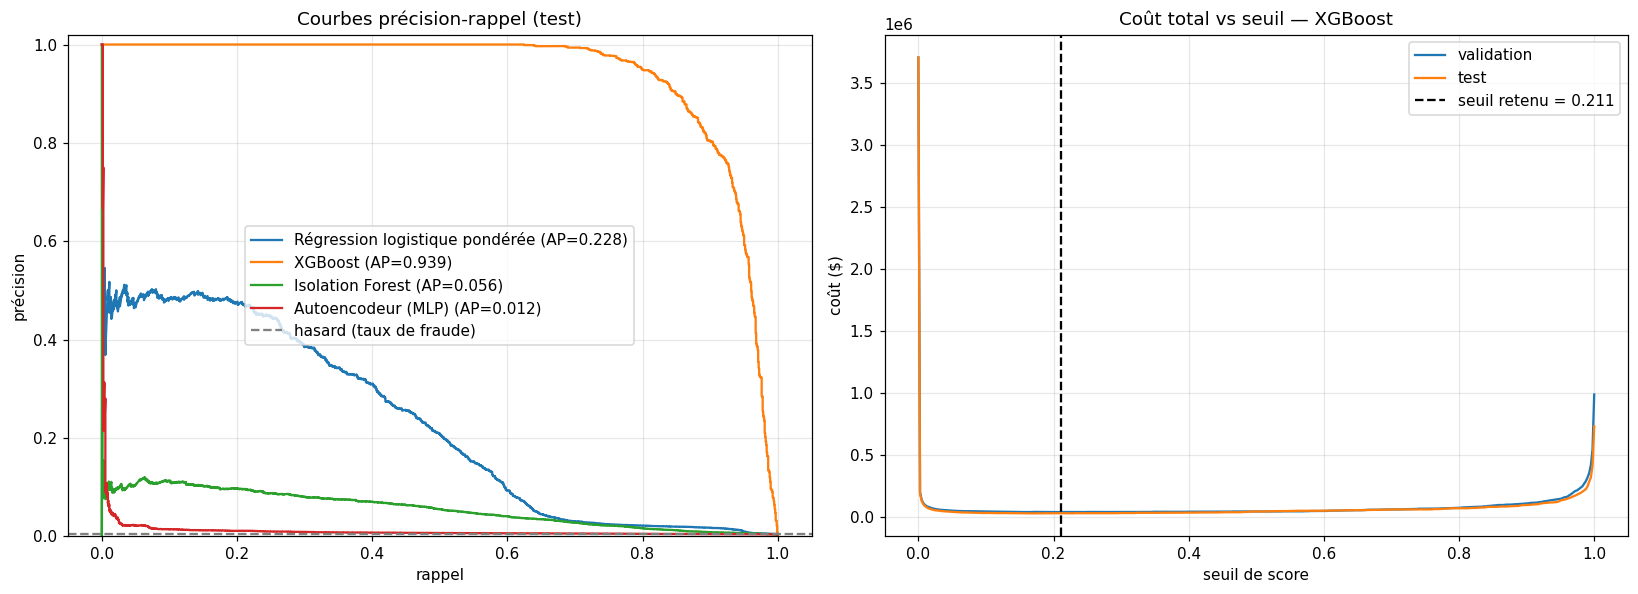

Seuil choisi sur la validation : 0.2107
  validation : coût 41,631 $ (vs 989,313 $ sans alerte)
  test       : coût 32,664 $ (vs 733,912 $ sans alerte) — 2,162 alertes, fraudes manquées 11,044 $
{'alertes': 2162, 'précision': 0.593, 'rappel': 0.9503, 'F2': 0.8481, 'MCC': np.float64(0.7496)}


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for nom, s in scores.items():
    p, r, _ = precision_recall_curve(yte, s['test'])
    ax[0].plot(r, p, label=f"{nom} (AP={average_precision_score(yte, s['test']):.3f})")
ax[0].axhline(yte.mean(), color='gray', ls='--', label='hasard (taux de fraude)')
ax[0].set(title='Courbes précision-rappel (test)', xlabel='rappel', ylabel='précision', ylim=(0, 1.02)); ax[0].legend()

grille = np.linspace(0, 1, 401)
sv, st_ = scores[NOM_FINAL]['val'], scores[NOM_FINAL]['test']
THR = seuils[NOM_FINAL]
ax[1].plot(grille, cout_vs_seuil(yva, amt_va, sv, COUT_ANALYSE, grille), label='validation')
ax[1].plot(grille, cout_vs_seuil(yte, amt_te, st_, COUT_ANALYSE, grille), label='test')
ax[1].axvline(THR, color='k', ls='--', label=f'seuil retenu = {THR:.3f}')
ax[1].set(title=f'Coût total vs seuil — {NOM_FINAL}', xlabel='seuil de score', ylabel='coût ($)'); ax[1].legend()
plt.tight_layout(); plt.show()

_, cv, c0v = seuil_optimal(yva, amt_va, sv, COUT_ANALYSE)
ct, mq, na = cout_au_seuil(yte, amt_te, st_, THR, COUT_ANALYSE)
print(f"Seuil choisi sur la validation : {THR:.4f}")
print(f"  validation : coût {cv:,.0f} $ (vs {c0v:,.0f} $ sans alerte)")
print(f"  test       : coût {ct:,.0f} $ (vs {amt_te[yte==1].sum():,.0f} $ sans alerte) — {na:,} alertes, fraudes manquées {mq:,.0f} $")
print({k: round(v, 4) for k, v in metriques_seuil(yte, st_, THR).items()})

### 🎛️ Tableau de bord interactif (curseurs de seuil et de budget, mise à jour en direct)
Règle appliquée : une transaction est alertée si son score ≥ seuil, **dans la limite du budget** (on garde les k mieux scorées). La version « application web » du même tableau de bord est fournie plus bas (Streamlit).

In [ ]:
import ipywidgets as widgets

ordre_te = np.argsort(-st_)
grille_c = np.linspace(0, 1, 201)

def tableau_de_bord(seuil, budget_pct, c_alerte):
    k = max(1, int(budget_pct / 100 * len(st_)))
    na = int(min(k, (st_ >= seuil).sum()))
    sel = ordre_te[:na]
    tp = int(yte[sel].sum())
    prec = tp / na if na else 0.0
    rap = tp / yte.sum()
    manque = amt_te[yte == 1].sum() - amt_te[sel][yte[sel] == 1].sum()
    cout = manque + c_alerte * na
    base = amt_te[yte == 1].sum()
    print(f"Alertes : {na:,} (budget max {k:,})   |   fraudes détectées : {tp:,}/{int(yte.sum()):,}")
    print(f"Précision : {prec:.1%}   Rappel : {rap:.1%}")
    print(f"Fraudes manquées : {manque:,.0f} $   Coût d'analyse : {c_alerte*na:,.0f} $   COÛT TOTAL : {cout:,.0f} $  (sans alerte : {base:,.0f} $)")
    plt.figure(figsize=(7, 3.2))
    plt.plot(grille_c, cout_vs_seuil(yte, amt_te, st_, c_alerte, grille_c))
    plt.axvline(seuil, color='r', ls='--'); plt.xlabel('seuil'); plt.ylabel('coût ($)'); plt.title('Coût total (test) vs seuil')
    plt.tight_layout(); plt.show()

w_seuil = widgets.FloatSlider(value=float(min(max(THR, 0), 1)), min=0, max=1, step=0.005, description='Seuil', readout_format='.3f', layout=widgets.Layout(width='500px'))
w_budget = widgets.FloatSlider(value=BUDGET_PCT, min=0.1, max=5, step=0.1, description='Budget %', layout=widgets.Layout(width='500px'))
w_cout = widgets.FloatSlider(value=COUT_ANALYSE, min=1, max=100, step=1, description='Coût/alerte $', layout=widgets.Layout(width='500px'))
display(widgets.VBox([w_seuil, w_budget, w_cout]),
        widgets.interactive_output(tableau_de_bord, {'seuil': w_seuil, 'budget_pct': w_budget, 'c_alerte': w_cout}))

Output()

# Module 5 — Explainable AI (SHAP)
* **Global** : beeswarm SHAP (échantillon de test : 2 500 transactions tirées au hasard + jusqu'à 500 fraudes, pour que les motifs de fraude soient visibles) et importance moyenne |SHAP| sur **tout** le test.
* **Local** : waterfall SHAP d'une alerte + **codes motifs** = les 3 à 5 variables qui ont le plus poussé le score vers « fraude ».

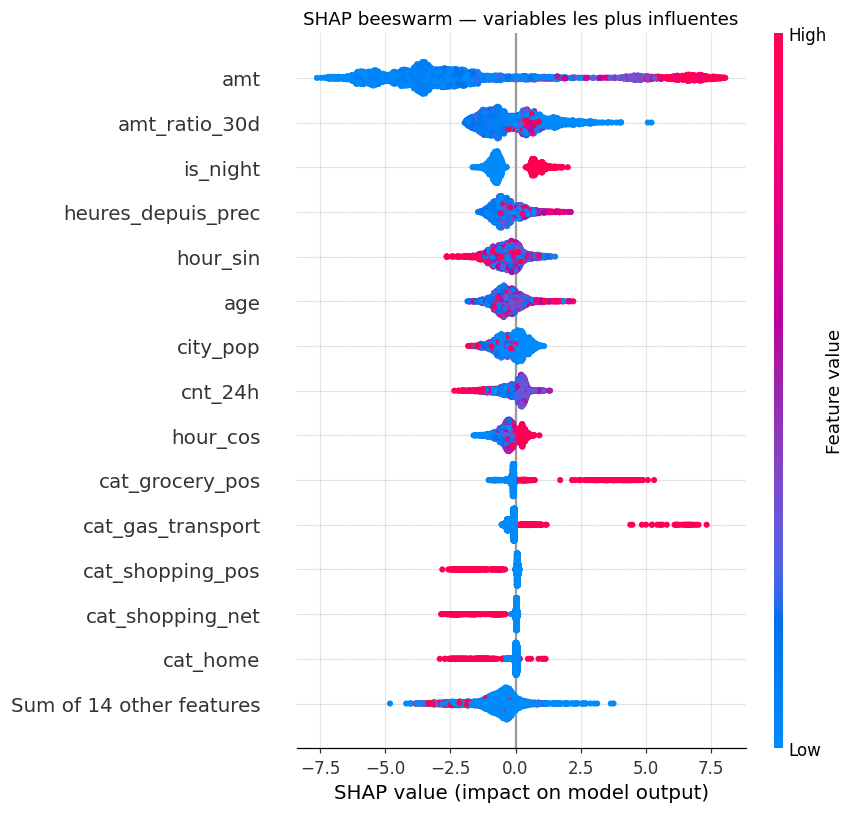

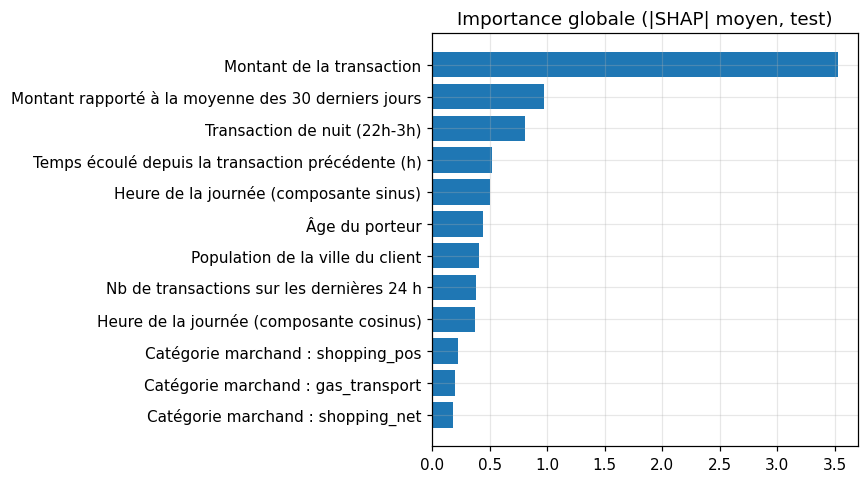

In [ ]:
import shap
explainer = shap.TreeExplainer(xgb_model)
rng = np.random.RandomState(SEED)
idx_s = np.unique(np.r_[rng.choice(len(Xte), size=min(2500, len(Xte)), replace=False),
                        rng.choice(np.flatnonzero(yte == 1), size=min(500, int(yte.sum())), replace=False)])
sv_ech = explainer(Xte.iloc[idx_s])
plt.figure()
shap.plots.beeswarm(sv_ech, max_display=15, show=False)
plt.title('SHAP beeswarm — variables les plus influentes'); plt.tight_layout()
plt.savefig('artifacts/shap_beeswarm.png', dpi=150, bbox_inches='tight'); plt.show()

# Contributions exactes (valeurs de Shapley pour les arbres) sur TOUT le test, via xgboost
contribs = xgb_model.get_booster().predict(xgb.DMatrix(Xte), pred_contribs=True).astype(np.float32)
np.save('artifacts/contribs.npy', contribs)
imp = pd.Series(np.abs(contribs[:, :-1]).mean(0), index=FEATURES).sort_values().tail(12)
plt.figure(figsize=(8, 4.5)); plt.barh([ff.LIBELLES[i][:55] for i in imp.index], imp.values, color='tab:blue')
plt.title('Importance globale (|SHAP| moyen, test)'); plt.tight_layout(); plt.show()


✅ Vraie fraude détectée (score le plus élevé)
  2020-12-22 23:13:39  |  misc_net  |  766.38 $  |  score = 1.000  |  réel : FRAUDE


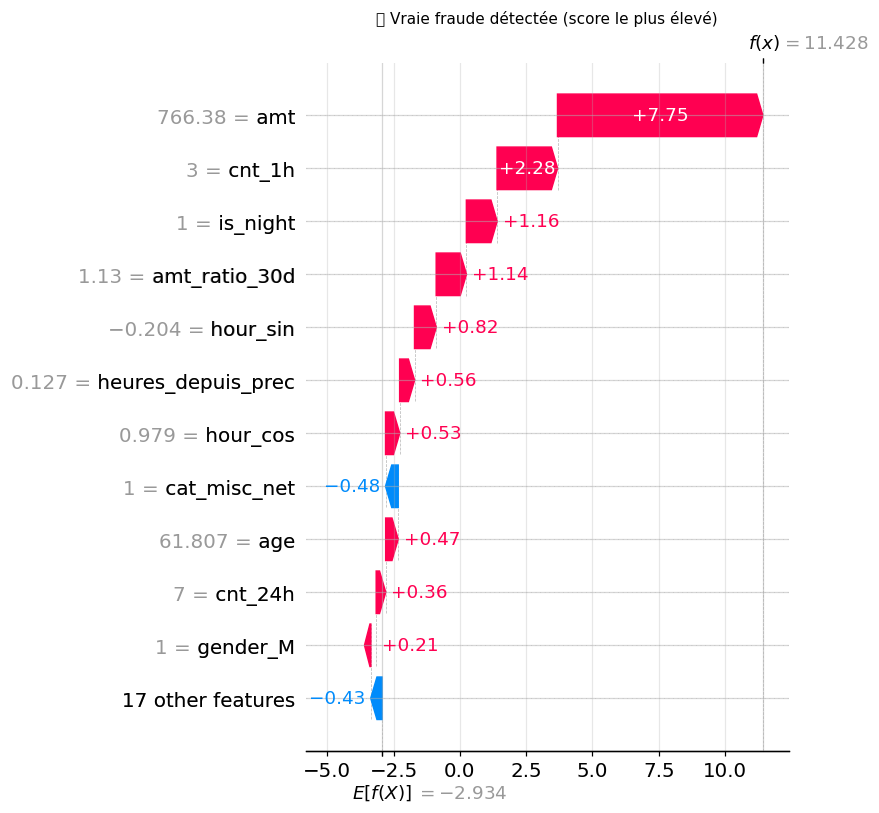

Codes motifs (3 à 5 variables ayant le plus contribué à l'alerte) :


,code,variable,motif,valeur,contribution
0,M1,amt,Montant de la transaction,766.380,7.745
1,M2,cnt_1h,Nb de transactions sur la dernière heure,3.000,2.280
2,M3,is_night,Transaction de nuit (22h-3h),1.000,1.159
3,M4,amt_ratio_30d,Montant rapporté à la moyenne des 30 derniers ...,1.130,1.139
4,M5,hour_sin,Heure de la journée (composante sinus),-0.204,0.818



⚠️ Fausse alerte (score le plus élevé parmi les légitimes)
  2020-12-27 00:00:08  |  shopping_net  |  843.12 $  |  score = 0.989  |  réel : légitime


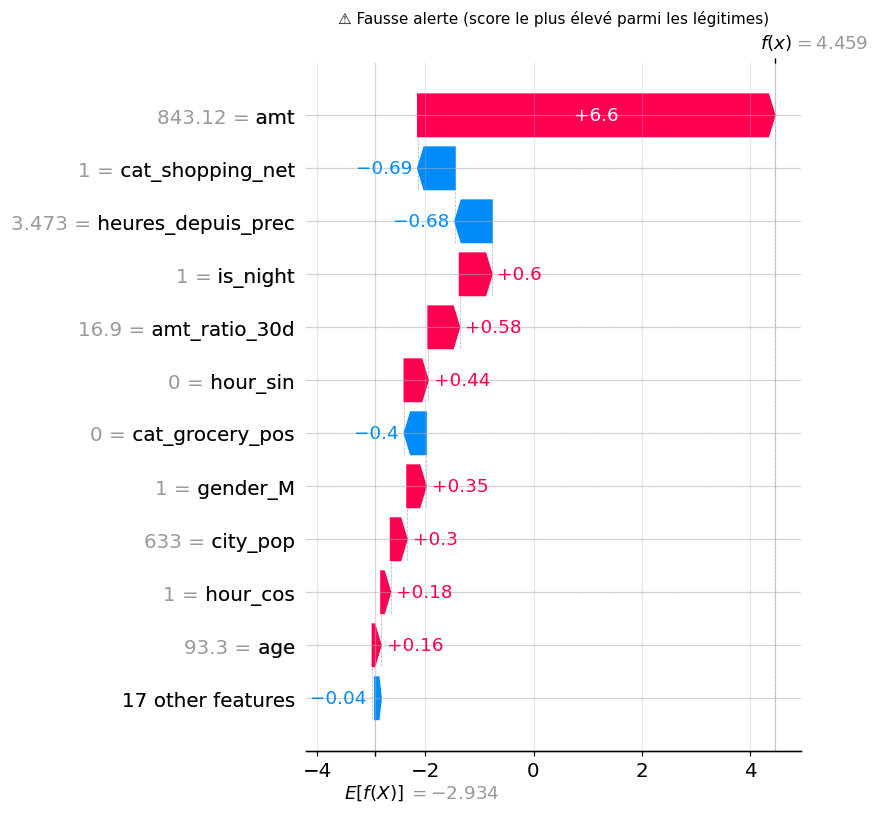

Codes motifs (3 à 5 variables ayant le plus contribué à l'alerte) :


,code,variable,motif,valeur,contribution
0,M1,amt,Montant de la transaction,843.12,6.598
1,M2,is_night,Transaction de nuit (22h-3h),1.00,0.598
2,M3,amt_ratio_30d,Montant rapporté à la moyenne des 30 derniers ...,16.90,0.581
3,M4,hour_sin,Heure de la journée (composante sinus),0.00,0.440
4,M5,gender_M,Genre (homme),1.00,0.351



❌ Fraude manquée (la mieux scorée sous le seuil)
  2020-09-06 22:04:35  |  food_dining  |  142.55 $  |  score = 0.209  |  réel : FRAUDE


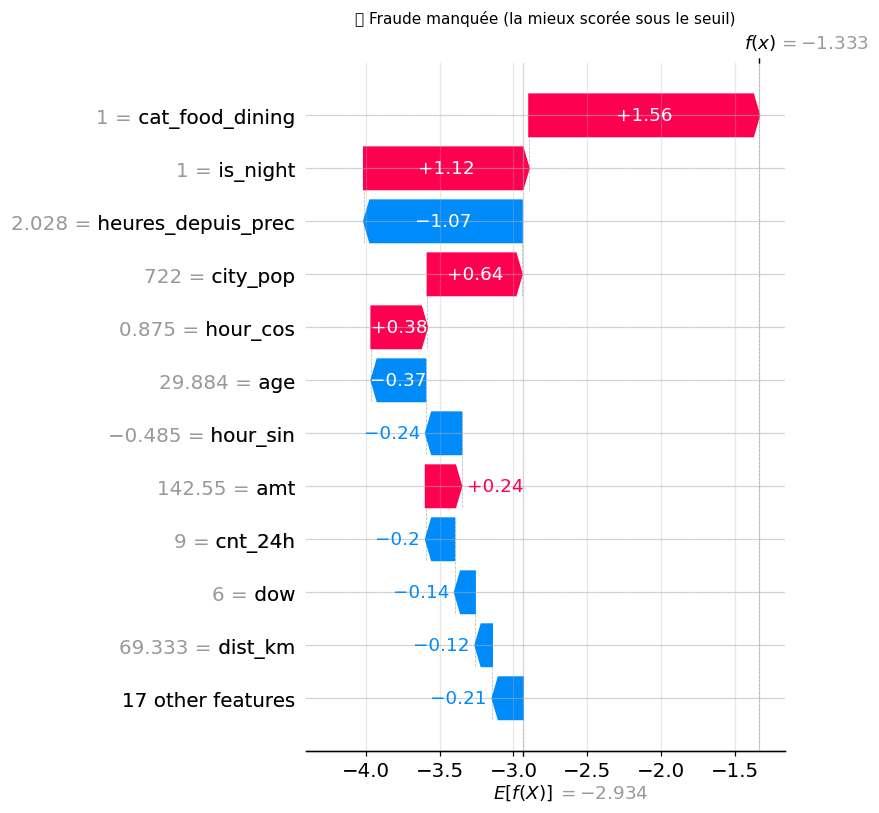

Codes motifs (3 à 5 variables ayant le plus contribué à l'alerte) :


,code,variable,motif,valeur,contribution
0,M1,cat_food_dining,Catégorie marchand : food_dining,1.000,1.561
1,M2,is_night,Transaction de nuit (22h-3h),1.000,1.119
2,M3,city_pop,Population de la ville du client,722.000,0.641
3,M4,hour_cos,Heure de la journée (composante cosinus),0.875,0.381
4,M5,amt,Montant de la transaction,142.550,0.244


In [ ]:
alertes_idx = np.flatnonzero(st_ >= THR)
vrais = alertes_idx[yte[alertes_idx] == 1]
faux = alertes_idx[yte[alertes_idx] == 0]
rates = np.flatnonzero((yte == 1) & (st_ < THR))
cas = []
if len(vrais): cas.append((vrais[np.argmax(st_[vrais])], '✅ Vraie fraude détectée (score le plus élevé)'))
if len(faux):  cas.append((faux[np.argmax(st_[faux])], '⚠️ Fausse alerte (score le plus élevé parmi les légitimes)'))
if len(rates): cas.append((rates[np.argmax(st_[rates])], '❌ Fraude manquée (la mieux scorée sous le seuil)'))

def afficher_alerte(i, titre):
    r = df.iloc[i2 + i]
    print(f"\n{'='*90}\n{titre}\n  {r.ts}  |  {r.category}  |  {r.amt:,.2f} $  |  score = {st_[i]:.3f}  |  réel : {'FRAUDE' if yte[i] else 'légitime'}")
    plt.figure(); shap.plots.waterfall(explainer(Xte.iloc[[i]])[0], max_display=12, show=False)
    plt.title(titre, fontsize=10); plt.tight_layout(); plt.show()
    print('Codes motifs (3 à 5 variables ayant le plus contribué à l\'alerte) :')
    display(pd.DataFrame(codes_motifs(contribs[i], Xte.iloc[i].values, n=5)))

for i, titre in cas:
    afficher_alerte(i, titre)

# Export des modèles et préparation de l'application locale

Les modèles entraînés et les artefacts nécessaires au tableau de bord sont sauvegardés pour une exécution autonome sur ordinateur. L'application Streamlit utilise directement ces fichiers.


In [ ]:
import joblib, shutil

# Modèle XGBoost utilisé par le tableau de bord
xgb_model.get_booster().save_model('artifacts/model.json')

# Export des modèles entraînés pour réutilisation hors notebook
os.makedirs('artifacts/models', exist_ok=True)
joblib.dump({
    'logistic_regression': lr,
    'standard_scaler': scaler,
    'isolation_forest': iso,
    'autoencoder_mlp': ae,
    'xgboost_imbalance_strategies': modeles_imb,
    'selected_xgboost_strategy': MEILLEURE,
}, 'artifacts/models/models.joblib', compress=3)

config = {'seuil': float(THR) if np.isfinite(THR) else 1.0, 'budget_pct': BUDGET_PCT, 'cout_analyse': COUT_ANALYSE,
          'modele': f'XGBoost — stratégie « {MEILLEURE} »', 'features': FEATURES,
          'pr_auc_test': float(average_precision_score(yte, st_))}
json.dump(config, open('artifacts/config.json', 'w'), indent=2, ensure_ascii=False)
Xte.assign(ts=df['ts'].values[i2:], category=df['category'].values[i2:], is_fraud=yte, score=st_)\
   .to_parquet('artifacts/app_data.parquet')
print('Artefacts exportés :', os.listdir('artifacts'))


Artefacts exportés : ['config.json', 'eda_monthly.csv', 'shap_beeswarm.png', 'models', 'contribs.npy', 'comparatif.csv', 'app_data.parquet', 'model.json']
